# 2. The experimental benchmark

**Goal:** compute the effect of a top-3 position on clicks in randomly ranked searches, where
position cannot depend on hotel quality. This is the truth the observational estimates are scored
against.

The benchmark lives in its own module (`benchmark.py`), the only code allowed to read the randomly
ranked arm for Q1. The observational specification was fixed in `config/spec_locked.yaml` first.

## Setup

Imports and configuration. Every threshold and setting comes from `config.yaml`. Set `SYNTHETIC = True` to run on the synthetic file built by `python -m causallab prepare --synthetic`.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import json
import numpy as np
import pandas as pd
from causallab.config import load_config, load_spec, results_dir

cfg = load_config()
SYNTHETIC = False   # True = run on the synthetic Expedia-like file (no Kaggle data needed)
pd.set_option("display.width", 140)

## Did randomisation work?

**What:** standardised mean differences (SMD) of hotel attributes between top-3 and positions 4-10,
inside the randomly ranked arm. SMD = difference in means divided by the pooled standard deviation.

**Why:** this is the causal counterpart of the sample-ratio check in an A/B test. If order is truly
random, hotel attributes cannot differ by position.

**Expect:** near zero for most attributes. Look closely at `prop_location_score2` and
`srch_query_affinity_score`: in this data they are **not** balanced. That is a finding, discussed below.

In [2]:
from causallab import benchmark
res = benchmark.run_untrimmed(cfg, SYNTHETIC, save=False)  # computed here, not written over results/
pd.Series(res["randomisation_balance_smd"]).sort_values(key=abs, ascending=False).round(3)

prop_location_score2         0.123
srch_query_affinity_score    0.076
prop_location_score1        -0.033
promotion_flag               0.030
prop_starrating              0.022
prop_log_historical_price    0.014
prop_brand_bool             -0.009
price_rank_pct              -0.008
log_price                    0.003
prop_review_score            0.003
log_distance                 0.001
dtype: float64

## Why are two scores unbalanced in a randomised arm?

**What:** the mean of each score by position in the randomly ranked arm.

**Why:** if a score falls steadily with position even though position was random, two explanations
are possible. (1) *Selection on clicks*: the file keeps only searches with a click, and in a randomly
ordered search a click is more likely when good hotels happen to land on top, so the kept searches have
better hotels on top. (2) *Click-log leakage*: the score may be computed partly from clicks that include
these searches, which would make it partly an outcome. The next cell tests the first explanation.

**Expect:** location score 2 falling from position 1 to position 10; star rating, which cannot come
from click logs, falling slightly too.

In [3]:
from causallab import data, features
exp = features.q1_rows(data.load_arm("experimental", cfg, SYNTHETIC))
exp.groupby("position")[["prop_location_score2", "srch_query_affinity_score", "prop_starrating", "prop_review_score"]].mean().round(3)

,prop_location_score2,srch_query_affinity_score,prop_starrating,prop_review_score
position,,,,
1,0.173,-17.802,3.333,3.946
2,0.168,-17.922,3.327,3.952
3,0.162,-18.304,3.321,3.957
4,0.155,-18.655,3.317,3.952
6,0.149,-18.777,3.309,3.949
7,0.146,-18.862,3.309,3.952
8,0.142,-19.045,3.303,3.950
9,0.139,-19.149,3.301,3.951
10,0.137,-19.021,3.300,3.947


## Testing selection on clicks

**What:** the imbalance between top-3 and positions 4-10, split by whether the search also had a click
below position 10.

**Why:** a search with a click below position 10 would be in the file whatever hotels sat on top, so
selection on clicks cannot create imbalance there. If the imbalance shrinks in that group, selection
explains part of it.

**Expect:** on the real sample the location-score imbalance halves, from about 0.12 overall to 0.06 in
searches with a click below position 10 (0.16 in searches without one). Star rating is nearly balanced
(about 0.02) in every group.

In [4]:
r = data.load_arm("experimental", cfg, SYNTHETIC)
low = r[r.position > 10].groupby("srch_id").click_bool.max()
q = exp.assign(click_below=exp.srch_id.map(low).fillna(0).astype(int))
def smd(d, c):
    a, b = d.loc[d.top3 == 1, c].dropna(), d.loc[d.top3 == 0, c].dropna()
    return (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)
groups = [("all searches", q), ("also a click below 10", q[q.click_below == 1]), ("no click below 10", q[q.click_below == 0])]
pd.DataFrame({name: {c: smd(d, c) for c in ["prop_location_score2", "srch_query_affinity_score", "prop_starrating"]}
              for name, d in groups}).round(3)

,all searches,also a click below 10,no click below 10
prop_location_score2,0.123,0.062,0.156
srch_query_affinity_score,0.076,0.051,0.091
prop_starrating,0.022,0.018,0.026


## The benchmark with a cluster bootstrap

**What:** difference in click rate, top-3 minus positions 4-10, with a 95% interval from 1,000
bootstrap draws that resample **whole searches**.

**Why:** resampling rows would treat the hotels in a search as independent and make the interval too
narrow. To make 1,000 draws fast, each search is reduced to four numbers (treated rows, treated
clicks, control rows, control clicks) and the draws are vectorised.

**Expect:** about 5 percentage points.

In [5]:
b = res["benchmark"]
print(f"Benchmark: {b['estimate']*100:.2f} pp, 95% interval [{b['ci_low']*100:.2f}, {b['ci_high']*100:.2f}], "
      f"{b['n_searches']:,} searches")

Benchmark: 5.25 pp, 95% interval [5.09, 5.42], 61,386 searches


## Do the two arms describe the same searches?

**What:** search-level covariates compared across arms, and a benchmark reweighted so the randomly
ranked searches look like the algorithm-ranked ones.

**Why:** if the arms differ, the benchmark answers a question about a different population.
Reweighting on covariates fixes covariate differences, but not selection on the outcome (every search
has a click).

**Expect:** longer stays and longer booking windows in the randomly ranked arm; a reweighted
benchmark close to the original.

In [6]:
pd.DataFrame(res["cross_arm_search_covariates"]).T.round(2)

,experimental,observational
srch_length_of_stay,2.94,2.15
srch_booking_window,49.74,32.95
srch_adults_count,2.05,1.95
srch_children_count,0.39,0.37
srch_room_count,1.12,1.13
srch_saturday_night_bool,0.48,0.51
n_results,24.18,25.09
visitor_same_country,0.60,0.65
site_5,0.58,0.62
site_14,0.10,0.10


In [7]:
w = res["benchmark_reweighted_to_observational"]
print(f"Reweighted benchmark: {w['estimate']*100:.2f} pp [{w['ci_low']*100:.2f}, {w['ci_high']*100:.2f}]")

Reweighted benchmark: 5.25 pp [5.08, 5.43]


## Click rate by position, both arms

**What:** the figure saved by the benchmark module.

**Why:** the gap between the two curves at the top is the confounding the observational estimators
must remove: in algorithm-ranked searches, top positions hold better hotels.

**Expect:** the observational curve above the experimental one at positions 1-4 and below it further
down: the ranker moves good hotels up and poor ones down. The dotted lines mark the reserved slots.

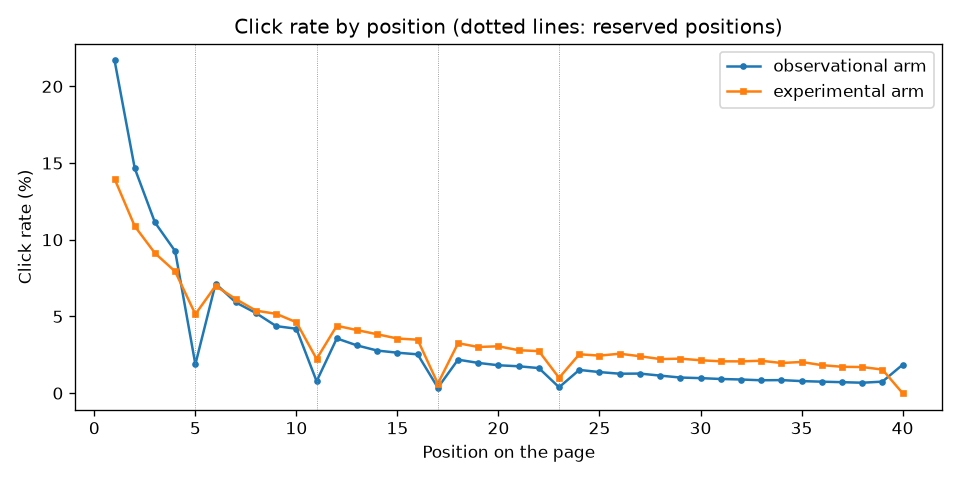

In [8]:
from IPython.display import Image
fig = results_dir(cfg) / "figures" / ("click_by_position_synthetic.png" if SYNTHETIC else "click_by_position.png")
if not fig.exists():  # `python -m causallab benchmark` saves it; draw it here only if missing
    benchmark.click_by_position_figure(cfg, SYNTHETIC)
Image(filename=str(fig))